# Vehicle Routing Problem: PSO vs Clustering + PSO

This notebook solves a real-world **Capacitated Vehicle Routing Problem with Time Windows and
Site-Dependent constraints (CVRPTW + SDVRP)** and compares two methods:

| Method | Idea |
|---|---|
| **Method 1: PSO** | Particle Swarm Optimization solves each delivery day as one problem. |
| **Method 2: Clustering + PSO** | Customers of each day are first grouped into geographic clusters, then PSO routes each cluster. |

The dataset contains 10 real delivery days from a distribution company in Bosnia and Herzegovina,
with road distances computed by GraphHopper / OpenStreetMap. Each day also has a reference solution
(benchmark) produced by the original authors of the dataset.

**Contents**

1. Setup
2. Data loading
3. Data validation
4. Exploratory data analysis
5. VRP model
6. Evaluator
7. Decoder

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DATA_DIR = Path("../data/raw")
RESULTS_DIR = Path("results")
FIGURES_DIR = RESULTS_DIR / "figures"
for folder in ["method1", "method2", "comparison", "figures"]:
    (RESULTS_DIR / folder).mkdir(parents=True, exist_ok=True)

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def save_figure(fig, name):
    # Save a figure to results/figures so it can be embedded in the README.
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def minutes_to_hhmm(minutes):
    minutes = int(round(minutes))
    return f"{minutes // 60:02d}:{minutes % 60:02d}"

## 2. Data loading

The raw data consists of nine Excel files (one table each) and one GPS log. Some tables are split
over several sheets (for example, the customer-to-customer distances do not fit in one `.xls` sheet),
so **every sheet is read and concatenated**. Columns are selected by their exact names, and empty
rows and the blank trailing column present in most files are removed.

| File | Content |
|---|---|
| `1_master_table_route_settings.xls` | One row per delivery day (`ROUTE_ID`), including the benchmark total cost |
| `2_detail_table_customers.xls` | Customers per day: location, time window, demand (kg, m³), service time |
| `3_detail_table_vehicles.xls` | Fleet per day: capacity (kg, m³), cost per km, working hours, benchmark results |
| `4_detail_table_depots.xls` | Depot location and opening hours |
| `5_detail_table_constraints_sdvrp.xls` | Customer–vehicle pairs that are **not allowed** (site-dependent constraint) |
| `6_detail_table_cust_depots_distances.xls` | Depot ↔ customer road distance and travel time (both directions) |
| `7_detail_table_cust_cust_distances.xls` | Customer → customer road distance and travel time |
| `8_detail_table_routes_RESULTS.xls` | Benchmark routes: stop order, arrival time, cumulative distance |
| `9_table_blocked_parts_of_the_road.xls` | Road points excluded when the distances were computed |

In [2]:
LOAD_LOG = []


def read_table(filename, key="ROUTE_ID"):
    # Read every sheet of an Excel file into one DataFrame, drop empty rows/columns and
    # rows without a key (stray cells outside the table). Dropped rows are logged.
    sheets = pd.read_excel(DATA_DIR / filename, sheet_name=None)
    df = pd.concat(sheets.values(), ignore_index=True)
    blank_cols = [c for c in df.columns if str(c).strip() == "" or str(c).startswith("Unnamed")]
    df = df.drop(columns=blank_cols).dropna(how="all")
    if key is not None:
        stray = df[key].isna()
        if stray.any():
            LOAD_LOG.append(f"{filename}: dropped {stray.sum()} stray rows without {key}")
        df = df[~stray]
    return df.reset_index(drop=True)


def load_raw_data():
    master = read_table("1_master_table_route_settings.xls")
    master = master.astype({"ROUTE_ID": int, "ROUTE_CODE": int})
    master["ROUTE_DATE"] = pd.to_datetime(master["ROUTE_DATE"], format="%d.%m.%Y")

    customers = read_table("2_detail_table_customers.xls")[[
        "ROUTE_ID", "CUSTOMER_NUMBER", "CUSTOMER_CODE",
        "CUSTOMER_LATITUDE", "CUSTOMER_LONGITUDE",
        "CUSTOMER_TIME_WINDOW_FROM_MIN", "CUSTOMER_TIME_WINDOW_TO_MIN",
        "NUMBER_OF_ARTICLES", "TOTAL_WEIGHT_KG", "TOTAL_VOLUME_M3",
        "CUSTOMER_DELIVERY_SERVICE_TIME_MIN",
    ]].astype({"ROUTE_ID": int, "CUSTOMER_CODE": int})

    vehicles = read_table("3_detail_table_vehicles.xls")
    vehicles = vehicles.astype({"ROUTE_ID": int, "VEHICLE_NUMBER": int})

    depots = read_table("4_detail_table_depots.xls")
    depots = depots.astype({"ROUTE_ID": int, "DEPOT_NUMBER": int, "DEPOT_CODE": int})

    sdvrp = read_table("5_detail_table_constraints_sdvrp.xls").rename(columns={
        "SDVRP_CONSTRAINT_CUSTOMER_CODE": "CUSTOMER_CODE",
        "SDVRP_CONSTRAINT_VEHICLE_CODE": "VEHICLE_CODE",
    })[["ROUTE_ID", "CUSTOMER_CODE", "VEHICLE_CODE"]].astype({"ROUTE_ID": int, "CUSTOMER_CODE": int})

    depot_dist = read_table("6_detail_table_cust_depots_distances.xls")[[
        "ROUTE_ID", "DEPOT_CODE", "CUSTOMER_CODE", "DIRECTION", "DISTANCE_KM", "TIME_DISTANCE_MIN",
    ]].astype({"ROUTE_ID": int, "DEPOT_CODE": int, "CUSTOMER_CODE": int})

    cust_dist = read_table("7_detail_table_cust_cust_distances.xls")[[
        "ROUTE_ID", "CUSTOMER_CODE_FROM", "CUSTOMER_CODE_TO", "DISTANCE_KM", "TIME_DISTANCE_MIN",
    ]].astype({"ROUTE_ID": int, "CUSTOMER_CODE_FROM": int, "CUSTOMER_CODE_TO": int})

    benchmark = read_table("8_detail_table_routes_RESULTS.xls").rename(columns={
        "CUSTOMER_IN_VEHICLE_ROUTE_ORDER_NUMBER": "STOP_ORDER",
        "COME_TO_THE_CUSTOMER_AT_MIN": "ARRIVAL_MIN",
        "DISTANCE_BETWEEN_TWO_LAST_CUSTOMERS_KM": "LEG_KM",
        "TOTAL_DISTANCE_TO_CUSTOMER_KM": "CUMULATIVE_KM",
    })[["ROUTE_ID", "VEHICLE_CODE", "STOP_ORDER", "CUSTOMER_CODE",
        "ARRIVAL_MIN", "LEG_KM", "CUMULATIVE_KM"]]
    benchmark = benchmark.astype({"ROUTE_ID": int, "STOP_ORDER": int, "CUSTOMER_CODE": int})

    blocked_roads = read_table("9_table_blocked_parts_of_the_road.xls", key=None)

    return {
        "master": master, "customers": customers, "vehicles": vehicles, "depots": depots,
        "sdvrp": sdvrp, "depot_dist": depot_dist, "cust_dist": cust_dist,
        "benchmark": benchmark, "blocked_roads": blocked_roads,
    }


data = load_raw_data()
print("\n".join(LOAD_LOG))
pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1]} for name, df in data.items()}).T

3_detail_table_vehicles.xls: dropped 6 stray rows without ROUTE_ID


,rows,columns
master,10,5
customers,896,11
vehicles,75,15
depots,10,7
sdvrp,252,3
depot_dist,1796,6
cust_dist,83748,5
benchmark,1002,7
blocked_roads,15,2


In [3]:
master, customers, vehicles, depots = data["master"], data["customers"], data["vehicles"], data["depots"]
sdvrp, depot_dist, cust_dist, benchmark = data["sdvrp"], data["depot_dist"], data["cust_dist"], data["benchmark"]
blocked_roads = data["blocked_roads"]

DEPOT_CODE = int(depots["DEPOT_CODE"].iloc[0])
ROUTE_IDS = master.sort_values("ROUTE_DATE")["ROUTE_ID"].tolist()
ROUTE_LABEL = {
    r.ROUTE_ID: f"{r.ROUTE_ID} ({r.ROUTE_DATE:%d.%m})" for r in master.itertuples()
}
print(f"Delivery days: {len(ROUTE_IDS)}  |  depot code: {DEPOT_CODE}")
customers.head()

Delivery days: 10  |  depot code: 1000


,ROUTE_ID,CUSTOMER_NUMBER,CUSTOMER_CODE,CUSTOMER_LATITUDE,CUSTOMER_LONGITUDE,CUSTOMER_TIME_WINDOW_FROM_MIN,CUSTOMER_TIME_WINDOW_TO_MIN,NUMBER_OF_ARTICLES,TOTAL_WEIGHT_KG,TOTAL_VOLUME_M3,CUSTOMER_DELIVERY_SERVICE_TIME_MIN
0,5097589,1,136500,43.114245,17.705782,481,961,12,57.358,0.137,16.488
1,5097589,2,15110,43.827830,17.606290,481,961,13,363.634,2.828,24.312
2,5097589,3,139621,43.824020,17.608030,481,961,13,24.107,0.072,16.260
3,5097589,4,924681,43.348339,17.805145,481,961,13,2.470,0.008,15.996
4,5097589,5,140660,43.198740,17.548540,481,961,5,76.524,0.297,16.104


## 3. Data validation

Every later step (evaluation, decoding, PSO, clustering) assumes the data is complete and
consistent. The checks below verify this explicitly. `FAIL` means the data cannot be used as is;
`WARN` means an anomaly that is documented and handled.

The benchmark routes are also checked, because they will later be used to validate our own cost
function: if our evaluator reproduces the benchmark cost, the problem is modelled correctly.

In [4]:
def validate(data):
    customers, vehicles, sdvrp = data["customers"], data["vehicles"], data["sdvrp"]
    depot_dist, cust_dist, benchmark = data["depot_dist"], data["cust_dist"], data["benchmark"]
    results = []

    def check(name, ok, detail="", warn_only=False):
        status = "PASS" if ok else ("WARN" if warn_only else "FAIL")
        results.append({"check": name, "status": status, "detail": detail})

    # --- consistency of route IDs and keys
    route_sets = {name: set(df["ROUTE_ID"]) for name, df in data.items() if "ROUTE_ID" in df}
    reference = set(data["master"]["ROUTE_ID"])
    mismatched = [name for name, ids in route_sets.items() if ids != reference]
    check("Same 10 route IDs in every table", not mismatched, ", ".join(mismatched))

    dup_cust = customers.duplicated(["ROUTE_ID", "CUSTOMER_CODE"]).sum()
    check("Customer code unique within each route", dup_cust == 0, f"{dup_cust} duplicates")

    dup_veh = vehicles.duplicated(["ROUTE_ID", "VEHICLE_CODE"]).sum()
    check("Vehicle code unique within each route", dup_veh == 0, f"{dup_veh} duplicates")

    coords = customers.groupby("CUSTOMER_CODE")[["CUSTOMER_LATITUDE", "CUSTOMER_LONGITUDE"]].nunique()
    moved = int((coords.max(axis=1) > 1).sum())
    check("Customer location identical across routes", moved == 0, f"{moved} customers moved")

    # --- distance matrices
    missing_cc, missing_dd, extra = [], [], []
    for rid, group in customers.groupby("ROUTE_ID"):
        codes = set(group["CUSTOMER_CODE"])
        cc = cust_dist[cust_dist["ROUTE_ID"] == rid]
        dd = depot_dist[depot_dist["ROUTE_ID"] == rid]
        n_cc = (cc["CUSTOMER_CODE_FROM"].isin(codes) & cc["CUSTOMER_CODE_TO"].isin(codes)).sum()
        n_dd = dd["CUSTOMER_CODE"].isin(codes).sum()
        if n_cc != len(codes) ** 2:
            missing_cc.append(f"{rid}: {n_cc}/{len(codes) ** 2}")
        if n_dd != 2 * len(codes):
            missing_dd.append(f"{rid}: {n_dd}/{2 * len(codes)}")
        unknown = (set(cc["CUSTOMER_CODE_FROM"]) | set(dd["CUSTOMER_CODE"])) - codes
        if unknown:
            extra.append(f"{rid}: {sorted(unknown)}")
    check("Customer-to-customer matrix complete (n x n per route)", not missing_cc, "; ".join(missing_cc))
    check("Depot-to-customer and customer-to-depot distances complete", not missing_dd, "; ".join(missing_dd))
    check("Distance tables contain only known customers", not extra,
          "; ".join(extra) + " (ignored)", warn_only=True)

    diagonal = cust_dist[cust_dist["CUSTOMER_CODE_FROM"] == cust_dist["CUSTOMER_CODE_TO"]]
    negative = (cust_dist[["DISTANCE_KM", "TIME_DISTANCE_MIN"]] < 0).any(axis=1).sum() + \
               (depot_dist[["DISTANCE_KM", "TIME_DISTANCE_MIN"]] < 0).any(axis=1).sum()
    check("Distances non-negative, zero on the diagonal",
          negative == 0 and (diagonal["DISTANCE_KM"] == 0).all(), f"{negative} negative values")

    # --- constraints
    known_pairs = customers[["ROUTE_ID", "CUSTOMER_CODE"]].merge(sdvrp, on=["ROUTE_ID", "CUSTOMER_CODE"])
    known_veh = known_pairs.merge(vehicles[["ROUTE_ID", "VEHICLE_CODE"]], on=["ROUTE_ID", "VEHICLE_CODE"])
    check("SDVRP pairs reference existing customers and vehicles", len(known_veh) == len(sdvrp),
          f"{len(sdvrp) - len(known_veh)} invalid pairs")

    largest = vehicles.groupby("ROUTE_ID")[["VEHICLE_TOTAL_WEIGHT_KG", "VEHICLE_TOTAL_VOLUME_M3"]].max()
    c = customers.join(largest, on="ROUTE_ID")
    too_big = ((c["TOTAL_WEIGHT_KG"] > c["VEHICLE_TOTAL_WEIGHT_KG"]) |
               (c["TOTAL_VOLUME_M3"] > c["VEHICLE_TOTAL_VOLUME_M3"])).sum()
    check("Every customer fits in the largest vehicle", too_big == 0, f"{too_big} customers too large")

    demand = customers.groupby("ROUTE_ID")[["TOTAL_WEIGHT_KG", "TOTAL_VOLUME_M3"]].sum()
    fleet = vehicles.groupby("ROUTE_ID")[["VEHICLE_TOTAL_WEIGHT_KG", "VEHICLE_TOTAL_VOLUME_M3"]].sum()
    over = ((demand.values > fleet.values).any(axis=1)).sum()
    check("Total demand within fleet capacity (kg and m3)", over == 0, f"{over} routes over capacity")

    odd_cost = vehicles[(vehicles["VEHICLE_VARIABLE_COST_KM"] < 0.1) | (vehicles["VEHICLE_VARIABLE_COST_KM"] > 1.0)]
    check("Vehicle cost per km in a plausible range (0.1-1.0)", odd_cost.empty,
          "; ".join(f"{r.ROUTE_ID}/{r.VEHICLE_CODE} = {r.VEHICLE_VARIABLE_COST_KM}" for r in odd_cost.itertuples())
          + " (kept as given)", warn_only=True)

    # --- benchmark solution
    stops = benchmark[benchmark["CUSTOMER_CODE"] != DEPOT_CODE]
    visits = stops.groupby(["ROUTE_ID", "CUSTOMER_CODE"]).size()
    expected = customers.set_index(["ROUTE_ID", "CUSTOMER_CODE"]).index
    check("Benchmark visits every customer exactly once",
          set(visits.index) == set(expected) and (visits == 1).all(),
          f"{len(set(expected) - set(visits.index))} unvisited, {(visits > 1).sum()} repeated")

    ends = benchmark.sort_values("STOP_ORDER").groupby(["ROUTE_ID", "VEHICLE_CODE"])["CUSTOMER_CODE"].agg(["first", "last"])
    check("Benchmark routes start and end at the depot",
          ((ends["first"] == DEPOT_CODE) & (ends["last"] == DEPOT_CODE)).all())

    violations = stops.merge(sdvrp, on=["ROUTE_ID", "CUSTOMER_CODE", "VEHICLE_CODE"])
    check("Benchmark respects SDVRP pairs", violations.empty, f"{len(violations)} violations")

    route_km = benchmark.groupby(["ROUTE_ID", "VEHICLE_CODE"])["CUMULATIVE_KM"].max().rename("KM")
    cost = vehicles.set_index(["ROUTE_ID", "VEHICLE_CODE"]).join(route_km, how="inner")
    cost["COST"] = cost["KM"] * cost["VEHICLE_VARIABLE_COST_KM"] + cost["VEHICLE_FIXED_COST_KM"]
    per_route = cost.groupby("ROUTE_ID")["COST"].sum()
    master_cost = data["master"].set_index("ROUTE_ID")["RESULT_TOTAL_COST_KM"]
    gap = (per_route - master_cost).abs().max()
    check("Benchmark cost = sum(km x cost per km) = master total", gap < 1e-3, f"max gap {gap:.6f}")

    return pd.DataFrame(results)


validation = validate(data)
validation.style.map(
    lambda s: {"PASS": "color: green", "WARN": "color: darkorange", "FAIL": "color: red"}.get(s, ""),
    subset=["status"],
)

,check,status,detail
0,Same 10 route IDs in every table,PASS,
1,Customer code unique within each route,PASS,0 duplicates
2,Vehicle code unique within each route,PASS,0 duplicates
3,Customer location identical across routes,PASS,0 customers moved
4,Customer-to-customer matrix complete (n x n per route),PASS,
5,Depot-to-customer and customer-to-depot distances complete,PASS,
6,Distance tables contain only known customers,WARN,"5052001: [938, 923635] (ignored)"
7,"Distances non-negative, zero on the diagonal",PASS,0 negative values
8,SDVRP pairs reference existing customers and vehicles,PASS,0 invalid pairs
9,Every customer fits in the largest vehicle,PASS,0 customers too large


In [5]:
assert not (validation["status"] == "FAIL").any(), "Data validation failed"
print(validation["status"].value_counts().to_string())

status
PASS    14
WARN     2


**Notes on the warnings**

- Route `5052001` has two customer codes in the distance tables that are not in its customer list.
  They are simply never looked up.
- Vehicle `B02-A-000` has a cost of 19.00 per km on routes `5064293` and `5072926`, a hundred times
  the 0.19 it has on route `5052001`, so most likely a typo. It is kept as given, because the
  benchmark was computed with the same data and does not use this vehicle on those two days. A good
  solver will avoid it as well.

## 4. Exploratory data analysis

In [6]:
def route_summary():
    rows = []
    bench_km = benchmark.groupby(["ROUTE_ID", "VEHICLE_CODE"])["CUMULATIVE_KM"].max()
    for rid in ROUTE_IDS:
        c = customers[customers["ROUTE_ID"] == rid]
        v = vehicles[vehicles["ROUTE_ID"] == rid]
        has_window = ~((c["CUSTOMER_TIME_WINDOW_FROM_MIN"] == 481) & (c["CUSTOMER_TIME_WINDOW_TO_MIN"] == 961))
        rows.append({
            "route": ROUTE_LABEL[rid],
            "customers": len(c),
            "vehicles": len(v),
            "demand_kg": c["TOTAL_WEIGHT_KG"].sum(),
            "fleet_kg": v["VEHICLE_TOTAL_WEIGHT_KG"].sum(),
            "demand_m3": c["TOTAL_VOLUME_M3"].sum(),
            "fleet_m3": v["VEHICLE_TOTAL_VOLUME_M3"].sum(),
            "specific_time_window": int(has_window.sum()),
            "sdvrp_pairs": int((sdvrp["ROUTE_ID"] == rid).sum()),
            "benchmark_vehicles": bench_km.loc[rid].size,
            "benchmark_km": bench_km.loc[rid].sum(),
            "benchmark_cost": master.set_index("ROUTE_ID").loc[rid, "RESULT_TOTAL_COST_KM"],
        })
    df = pd.DataFrame(rows)
    df["util_kg_%"] = 100 * df["demand_kg"] / df["fleet_kg"]
    df["util_m3_%"] = 100 * df["demand_m3"] / df["fleet_m3"]
    return df


summary = route_summary()
summary.round(1)

,route,customers,vehicles,demand_kg,fleet_kg,demand_m3,fleet_m3,specific_time_window,sdvrp_pairs,benchmark_vehicles,benchmark_km,benchmark_cost,util_kg_%,util_m3_%
0,5084612 (01.08),86,7,10064.6,34991.0,24.8,75.5,29,51,5,928.5,184.4,28.8,32.9
1,5072926 (02.08),105,8,10637.9,26606.0,30.4,65.7,52,43,6,781.9,163.5,40.0,46.3
2,5064293 (05.08),90,8,8888.8,26606.0,24.5,65.7,30,8,5,883.0,178.9,33.4,37.3
3,5052001 (26.08),106,8,9742.1,27206.0,28.8,65.7,33,17,6,1079.4,208.6,35.8,43.9
4,5041384 (11.09),97,8,11194.8,27206.0,40.9,65.7,27,18,6,651.9,130.1,41.1,62.2
5,5038453 (17.09),51,8,4243.7,27206.0,16.5,65.7,14,30,4,493.3,95.2,15.6,25.1
6,5092554 (24.09),68,7,4174.3,19935.0,13.3,50.2,27,27,4,603.9,114.7,20.9,26.4
7,5030001 (25.09),89,7,12717.2,19935.0,32.2,50.2,33,12,5,843.0,166.7,63.8,64.2
8,5110801 (27.09),92,7,8125.8,19935.0,29.1,50.2,44,27,6,792.7,160.8,40.8,58.0
9,5097589 (30.09),112,7,9309.6,19935.0,41.7,50.2,48,19,6,929.2,183.6,46.7,83.0


In [7]:
print(f"Customer visits      : {len(customers)} (unique customers: {customers['CUSTOMER_CODE'].nunique()})")
print(f"Customers per day    : {summary['customers'].min()}-{summary['customers'].max()}")
print(f"Vehicles per day     : {summary['vehicles'].min()}-{summary['vehicles'].max()}"
      f" (benchmark uses {summary['benchmark_vehicles'].min()}-{summary['benchmark_vehicles'].max()})")
print(f"Fleet utilisation kg : {summary['util_kg_%'].min():.0f}%-{summary['util_kg_%'].max():.0f}%")
print(f"Fleet utilisation m3 : {summary['util_m3_%'].min():.0f}%-{summary['util_m3_%'].max():.0f}%")
print(f"Benchmark total cost : {summary['benchmark_cost'].sum():.2f} KM over {summary['benchmark_km'].sum():.1f} km")

pairs = cust_dist.merge(
    cust_dist, left_on=["ROUTE_ID", "CUSTOMER_CODE_FROM", "CUSTOMER_CODE_TO"],
    right_on=["ROUTE_ID", "CUSTOMER_CODE_TO", "CUSTOMER_CODE_FROM"], suffixes=("", "_BACK"),
)
pairs = pairs[pairs["CUSTOMER_CODE_FROM"] != pairs["CUSTOMER_CODE_TO"]]
asym = (pairs["DISTANCE_KM"] - pairs["DISTANCE_KM_BACK"]).abs()
print(f"Asymmetric distances : {100 * (asym > 0.01).mean():.0f}% of pairs differ, mean |A->B - B->A| = {asym.mean():.2f} km")

Customer visits      : 896 (unique customers: 509)
Customers per day    : 51-112
Vehicles per day     : 7-8 (benchmark uses 4-6)
Fleet utilisation kg : 16%-64%
Fleet utilisation m3 : 25%-83%
Benchmark total cost : 1586.59 KM over 7986.7 km
Asymmetric distances : 86% of pairs differ, mean |A->B - B->A| = 0.32 km


### Customer locations

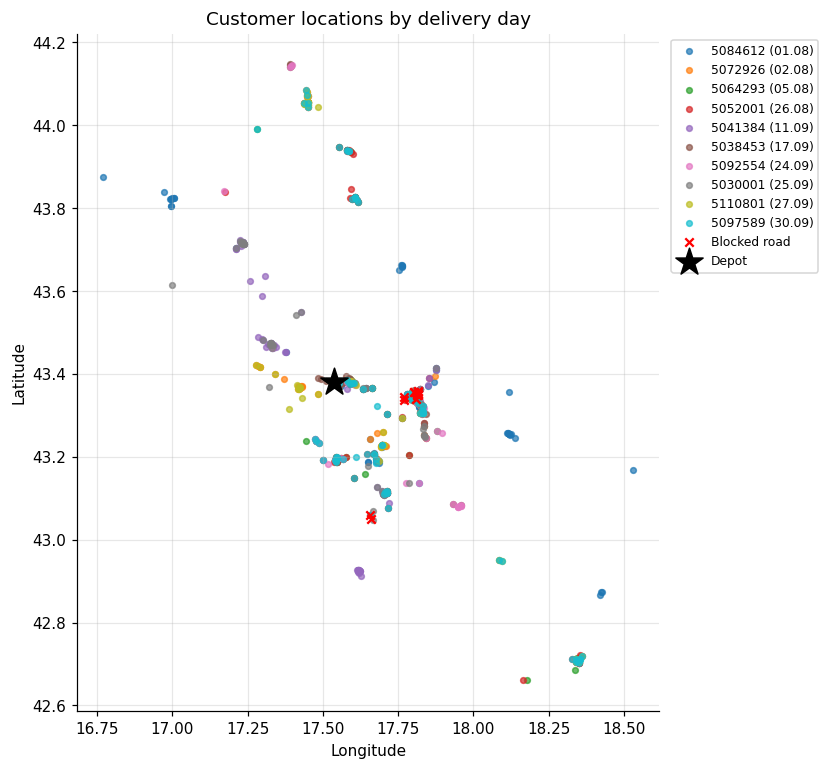

In [8]:
depot = depots.iloc[0]
fig, ax = plt.subplots(figsize=(9, 8))
colors = plt.get_cmap("tab10")
for i, rid in enumerate(ROUTE_IDS):
    c = customers[customers["ROUTE_ID"] == rid]
    ax.scatter(c["CUSTOMER_LONGITUDE"], c["CUSTOMER_LATITUDE"], s=14, alpha=0.7,
               color=colors(i), label=ROUTE_LABEL[rid])
ax.scatter(blocked_roads["BLOCKED_PART_OF_THE_ROAD_LON"], blocked_roads["BLOCKED_PART_OF_THE_ROAD_LAT"],
           marker="x", color="red", s=30, label="Blocked road")
ax.scatter(depot["DEPOT_LONGITUDE"], depot["DEPOT_LATITUDE"], marker="*", s=350,
           color="black", zorder=5, label="Depot")
ax.set_aspect(1 / np.cos(np.radians(depot["DEPOT_LATITUDE"])))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Customer locations by delivery day")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
save_figure(fig, "eda_customer_map")
plt.show()

### Demand, fleet and time windows

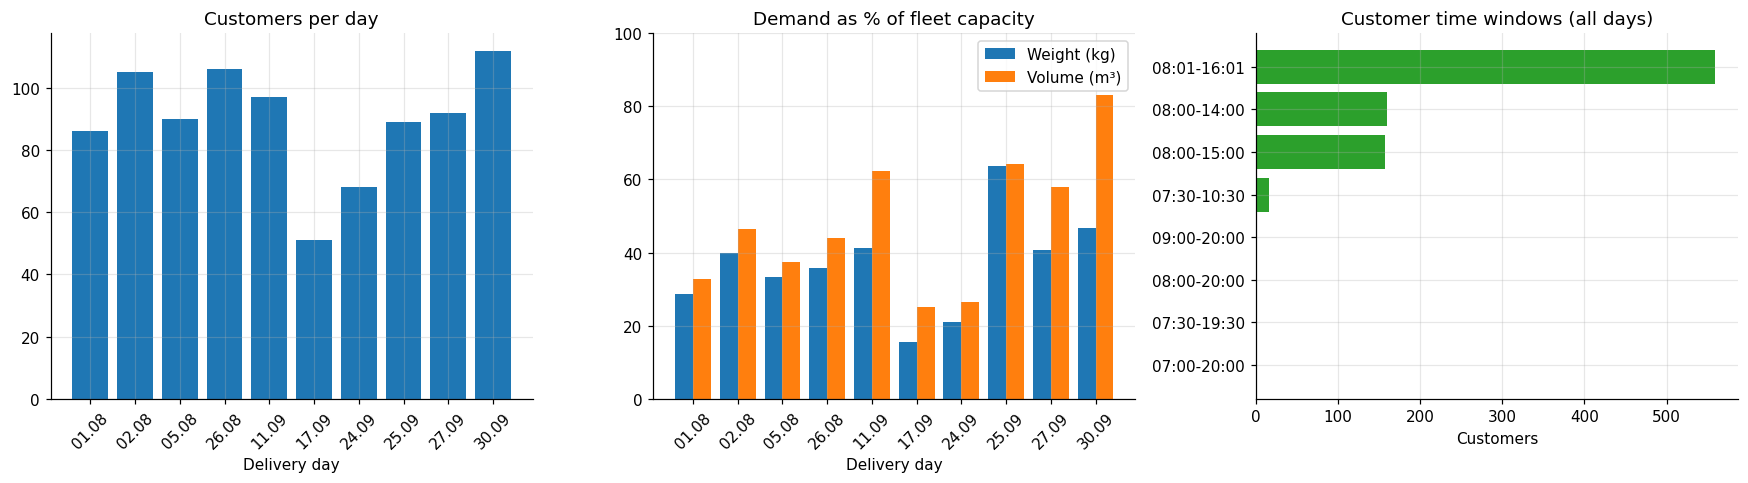

In [9]:
labels = [f"{d:%d.%m}" for d in master.set_index("ROUTE_ID").loc[ROUTE_IDS, "ROUTE_DATE"]]
x = np.arange(len(summary))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].bar(x, summary["customers"], color="tab:blue")
axes[0].set_title("Customers per day")

axes[1].bar(x - 0.2, summary["util_kg_%"], width=0.4, label="Weight (kg)", color="tab:blue")
axes[1].bar(x + 0.2, summary["util_m3_%"], width=0.4, label="Volume (m³)", color="tab:orange")
axes[1].set_title("Demand as % of fleet capacity")
axes[1].set_ylim(0, 100)
axes[1].legend()

windows = customers.groupby(["CUSTOMER_TIME_WINDOW_FROM_MIN", "CUSTOMER_TIME_WINDOW_TO_MIN"]).size()
windows = windows.sort_values()
window_labels = [f"{minutes_to_hhmm(a)}-{minutes_to_hhmm(b)}" for a, b in windows.index]
axes[2].barh(window_labels, windows.values, color="tab:green")
axes[2].set_title("Customer time windows (all days)")
axes[2].set_xlabel("Customers")

for ax in axes[:2]:
    ax.set_xticks(x, labels, rotation=45)
    ax.set_xlabel("Delivery day")
fig.tight_layout()
save_figure(fig, "eda_route_overview")
plt.show()

### Key observations

- **10 independent problems.** Each `ROUTE_ID` is a separate delivery day with its own customers
  (51–112), fleet (7–8 vehicles) and distance matrix. The same customer can appear on several days
  (896 visits, 509 unique customers), so days must never be mixed.
- **One depot** serves every day. Distances are real road distances and are **asymmetric**
  (A→B differs from B→A for most pairs), so the depot→customer and customer→depot directions must
  be kept separate.
- **Volume is the tighter capacity.** Demand uses up to 83% of the fleet volume but at most 64% of
  its weight, so both capacities have to be checked.
- **Time windows matter for 38% of the customer visits.** The window 08:01–16:01 is the default
  (shown as "-" in the benchmark); the other windows are tighter, the narrowest being 07:30–10:30.
- **The benchmark is a reliable reference.** It visits every customer once, respects all SDVRP
  pairs, and its cost is exactly the sum of route distance × vehicle cost per km. This formula will
  be the objective function of both methods.

## 5. VRP model

Each delivery day is converted into one `VRPInstance`: plain NumPy arrays that the evaluator,
decoder and PSO can use directly, without touching the DataFrames again. Both methods use exactly
the same instances, so any difference in their results comes from the method itself.

**Node indexing.** Node `0` is the depot and nodes `1..n` are the customers of that day (in the
order of `CUSTOMER_NUMBER`). The original customer and vehicle codes are kept for the output files.

| Field | Shape | Meaning |
|---|---|---|
| `dist_km`, `time_min` | (n+1) × (n+1) | Road distance and travel time from node *i* to node *j*. Asymmetric: row 0 uses `DEPOT->CUSTOMER`, column 0 uses `CUSTOMER->DEPOT` |
| `demand_kg`, `demand_m3` | n+1 | Weight and volume to deliver (0 for the depot) |
| `tw_start`, `tw_end` | n+1 | Customer time window in minutes after midnight (depot: opening hours) |
| `service_min` | n+1 | Unloading time at the customer |
| `cap_kg`, `cap_m3` | V | Vehicle capacities |
| `cost_per_km`, `fixed_cost` | V | Vehicle costs (the objective) |
| `veh_start`, `veh_end` | V | Vehicle working hours |
| `allowed` | (n+1) × V | `False` if the SDVRP table forbids vehicle *v* to serve customer *i* |

In [10]:
from dataclasses import dataclass


@dataclass
class VRPInstance:
    route_id: int
    date: pd.Timestamp
    customer_codes: np.ndarray   # length n, customer of node i is customer_codes[i - 1]
    vehicle_codes: np.ndarray    # length V
    coords: np.ndarray           # (n+1, 2) latitude, longitude; row 0 is the depot
    dist_km: np.ndarray          # (n+1, n+1)
    time_min: np.ndarray         # (n+1, n+1)
    demand_kg: np.ndarray        # (n+1,)
    demand_m3: np.ndarray        # (n+1,)
    tw_start: np.ndarray         # (n+1,)
    tw_end: np.ndarray           # (n+1,)
    service_min: np.ndarray      # (n+1,)
    cap_kg: np.ndarray           # (V,)
    cap_m3: np.ndarray           # (V,)
    cost_per_km: np.ndarray      # (V,)
    fixed_cost: np.ndarray       # (V,)
    veh_start: np.ndarray        # (V,)
    veh_end: np.ndarray          # (V,)
    allowed: np.ndarray          # (n+1, V) bool

    @property
    def n_customers(self):
        return len(self.customer_codes)

    @property
    def n_vehicles(self):
        return len(self.vehicle_codes)

    @property
    def depot_open(self):
        return self.tw_start[0]

    @property
    def depot_close(self):
        return self.tw_end[0]


def build_instance(route_id):
    c = customers[customers["ROUTE_ID"] == route_id].sort_values("CUSTOMER_NUMBER").reset_index(drop=True)
    v = vehicles[vehicles["ROUTE_ID"] == route_id].sort_values("VEHICLE_NUMBER").reset_index(drop=True)
    d = depots[depots["ROUTE_ID"] == route_id].iloc[0]

    codes = c["CUSTOMER_CODE"].to_numpy()
    node_of = {code: i + 1 for i, code in enumerate(codes)}
    veh_of = {code: k for k, code in enumerate(v["VEHICLE_CODE"])}
    n = len(codes)

    # Distance and time matrices, filled from the long tables.
    dist = np.full((n + 1, n + 1), np.nan)
    time = np.full((n + 1, n + 1), np.nan)
    np.fill_diagonal(dist, 0.0)
    np.fill_diagonal(time, 0.0)

    cc = cust_dist[(cust_dist["ROUTE_ID"] == route_id)
                   & cust_dist["CUSTOMER_CODE_FROM"].isin(node_of)
                   & cust_dist["CUSTOMER_CODE_TO"].isin(node_of)]
    i = cc["CUSTOMER_CODE_FROM"].map(node_of).to_numpy()
    j = cc["CUSTOMER_CODE_TO"].map(node_of).to_numpy()
    dist[i, j] = cc["DISTANCE_KM"].to_numpy()
    time[i, j] = cc["TIME_DISTANCE_MIN"].to_numpy()

    dd = depot_dist[(depot_dist["ROUTE_ID"] == route_id) & depot_dist["CUSTOMER_CODE"].isin(node_of)]
    out = dd[dd["DIRECTION"] == "DEPOT->CUSTOMER"]
    back = dd[dd["DIRECTION"] == "CUSTOMER->DEPOT"]
    dist[0, out["CUSTOMER_CODE"].map(node_of)] = out["DISTANCE_KM"].to_numpy()
    time[0, out["CUSTOMER_CODE"].map(node_of)] = out["TIME_DISTANCE_MIN"].to_numpy()
    dist[back["CUSTOMER_CODE"].map(node_of), 0] = back["DISTANCE_KM"].to_numpy()
    time[back["CUSTOMER_CODE"].map(node_of), 0] = back["TIME_DISTANCE_MIN"].to_numpy()

    def with_depot(values, depot_value=0.0):
        return np.concatenate([[depot_value], np.asarray(values, dtype=float)])

    # Site-dependent constraint: forbidden customer-vehicle pairs.
    allowed = np.ones((n + 1, len(v)), dtype=bool)
    forbidden = sdvrp[sdvrp["ROUTE_ID"] == route_id]
    allowed[forbidden["CUSTOMER_CODE"].map(node_of), forbidden["VEHICLE_CODE"].map(veh_of)] = False

    return VRPInstance(
        route_id=route_id,
        date=master.set_index("ROUTE_ID").loc[route_id, "ROUTE_DATE"],
        customer_codes=codes,
        vehicle_codes=v["VEHICLE_CODE"].to_numpy(),
        coords=np.vstack([[d["DEPOT_LATITUDE"], d["DEPOT_LONGITUDE"]],
                          c[["CUSTOMER_LATITUDE", "CUSTOMER_LONGITUDE"]].to_numpy()]),
        dist_km=dist,
        time_min=time,
        demand_kg=with_depot(c["TOTAL_WEIGHT_KG"]),
        demand_m3=with_depot(c["TOTAL_VOLUME_M3"]),
        tw_start=with_depot(c["CUSTOMER_TIME_WINDOW_FROM_MIN"], d["DEPOT_AVAILABLE_TIME_FROM_MIN"]),
        tw_end=with_depot(c["CUSTOMER_TIME_WINDOW_TO_MIN"], d["DEPOT_AVAILABLE_TIME_TO_MIN"]),
        service_min=with_depot(c["CUSTOMER_DELIVERY_SERVICE_TIME_MIN"]),
        cap_kg=v["VEHICLE_TOTAL_WEIGHT_KG"].to_numpy(float),
        cap_m3=v["VEHICLE_TOTAL_VOLUME_M3"].to_numpy(float),
        cost_per_km=v["VEHICLE_VARIABLE_COST_KM"].to_numpy(float),
        fixed_cost=v["VEHICLE_FIXED_COST_KM"].to_numpy(float),
        veh_start=v["VEHICLE_AVAILABLE_TIME_FROM_MIN"].to_numpy(float),
        veh_end=v["VEHICLE_AVAILABLE_TIME_TO_MIN"].to_numpy(float),
        allowed=allowed,
    )


INSTANCES = {rid: build_instance(rid) for rid in ROUTE_IDS}
print(f"Built {len(INSTANCES)} instances")

Built 10 instances


### Instance checks

The instances are checked against the raw tables before anything is built on top of them:

- **Complete matrices**: no missing distance or travel time.
- **Spot check**: 200 random entries per day are compared with the original distance tables
  (both directions to and from the depot included).
- **Every customer can be served alone**: for each customer there is at least one allowed vehicle
  with enough capacity that can leave the depot, arrive before the window closes, and return before
  the vehicle and depot close. If this failed, no solver could ever serve that customer.

In [11]:
def raw_distance(route_id, code_from, code_to):
    # Look a distance up directly in the raw tables (None = depot).
    if code_from == code_to:
        return 0.0
    if code_from is None:
        row = depot_dist.query("ROUTE_ID == @route_id and CUSTOMER_CODE == @code_to and DIRECTION == 'DEPOT->CUSTOMER'")
    elif code_to is None:
        row = depot_dist.query("ROUTE_ID == @route_id and CUSTOMER_CODE == @code_from and DIRECTION == 'CUSTOMER->DEPOT'")
    else:
        row = cust_dist.query("ROUTE_ID == @route_id and CUSTOMER_CODE_FROM == @code_from and CUSTOMER_CODE_TO == @code_to")
    return float(row["DISTANCE_KM"].iloc[0])


def check_instance(inst, n_samples=200):
    n = inst.n_customers
    node_code = [None] + list(inst.customer_codes)
    samples = rng.integers(0, n + 1, size=(n_samples, 2))
    spot_ok = all(
        np.isclose(inst.dist_km[i, j], raw_distance(inst.route_id, node_code[i], node_code[j]))
        for i, j in samples
    )

    # Earliest possible single-customer trip for every customer-vehicle pair.
    depart = np.maximum(inst.veh_start, inst.depot_open)                       # (V,)
    arrive = depart[None, :] + inst.time_min[0, 1:][:, None]                  # (n, V)
    start = np.maximum(arrive, inst.tw_start[1:, None])
    back = start + inst.service_min[1:, None] + inst.time_min[1:, 0][:, None]
    feasible = (
        inst.allowed[1:]
        & (inst.demand_kg[1:, None] <= inst.cap_kg[None, :])
        & (inst.demand_m3[1:, None] <= inst.cap_m3[None, :])
        & (start <= inst.tw_end[1:, None])
        & (back <= np.minimum(inst.veh_end, inst.depot_close)[None, :])
    )

    forbidden = (~inst.allowed[1:]).sum()
    return {
        "route": ROUTE_LABEL[inst.route_id],
        "customers": n,
        "vehicles": inst.n_vehicles,
        "matrix": f"{n + 1}x{n + 1}",
        "missing_values": int(np.isnan(inst.dist_km).sum() + np.isnan(inst.time_min).sum()),
        "spot_check": "OK" if spot_ok else "MISMATCH",
        "forbidden_pairs": int(forbidden),
        "customers_servable_alone": f"{feasible.any(axis=1).sum()}/{n}",
    }


instance_checks = pd.DataFrame([check_instance(inst) for inst in INSTANCES.values()])
assert (instance_checks["missing_values"] == 0).all()
assert (instance_checks["spot_check"] == "OK").all()
instance_checks

,route,customers,vehicles,matrix,missing_values,spot_check,forbidden_pairs,customers_servable_alone
0,5084612 (01.08),86,7,87x87,0,OK,51,86/86
1,5072926 (02.08),105,8,106x106,0,OK,43,105/105
2,5064293 (05.08),90,8,91x91,0,OK,8,90/90
3,5052001 (26.08),106,8,107x107,0,OK,17,106/106
4,5041384 (11.09),97,8,98x98,0,OK,18,97/97
5,5038453 (17.09),51,8,52x52,0,OK,30,51/51
6,5092554 (24.09),68,7,69x69,0,OK,27,68/68
7,5030001 (25.09),89,7,90x90,0,OK,12,89/89
8,5110801 (27.09),92,7,93x93,0,OK,27,92/92
9,5097589 (30.09),112,7,113x113,0,OK,19,112/112


### Properties of the road network

Road distances do not always satisfy the triangle inequality (a detour through a third customer can
be shorter than the direct road, for example because of one-way streets or the blocked road
sections). This matters for the insertion decoder later: inserting a customer between two others can
occasionally *reduce* the route length, which the decoder must handle correctly.

In [12]:
def network_properties(inst):
    d = inst.dist_km
    asym = np.abs(d - d.T)[np.triu_indices_from(d, k=1)]
    # d[i, k] > d[i, j] + d[j, k] for distinct i, j, k
    shortcut = d[:, None, :] > d[:, :, None] + d[None, :, :] + 1e-9
    n = len(d)
    triples = n * (n - 1) * (n - 2)
    return {
        "route": ROUTE_LABEL[inst.route_id],
        "mean_km_between_customers": d[1:, 1:][~np.eye(n - 1, dtype=bool)].mean(),
        "max_km_from_depot": d[0, 1:].max(),
        "asymmetric_pairs_%": 100 * (asym > 0.01).mean(),
        "triangle_violations_%": 100 * shortcut.sum() / triples,
    }


pd.DataFrame([network_properties(inst) for inst in INSTANCES.values()]).round(2)

,route,mean_km_between_customers,max_km_from_depot,asymmetric_pairs_%,triangle_violations_%
0,5084612 (01.08),60.39,122.39,84.55,1.26
1,5072926 (02.08),60.03,122.38,84.89,1.33
2,5064293 (05.08),66.02,141.04,88.91,1.02
3,5052001 (26.08),61.88,142.53,87.32,1.44
4,5041384 (11.09),56.16,100.15,85.69,1.42
5,5038453 (17.09),43.45,127.21,87.56,1.02
6,5092554 (24.09),45.98,127.20,89.47,1.00
7,5030001 (25.09),41.45,71.10,85.67,1.45
8,5110801 (27.09),69.10,124.54,83.43,1.11
9,5097589 (30.09),63.86,126.78,88.23,0.73


In [13]:
example = INSTANCES[ROUTE_IDS[0]]
print(f"Example instance: route {example.route_id} ({example.date:%d.%m.%Y})")
print(f"  customers {example.n_customers}, vehicles {example.n_vehicles}")
print(f"  depot open {minutes_to_hhmm(example.depot_open)}-{minutes_to_hhmm(example.depot_close)}")
pd.DataFrame({
    "vehicle": example.vehicle_codes,
    "cap_kg": example.cap_kg,
    "cap_m3": example.cap_m3,
    "cost_per_km": example.cost_per_km,
    "hours": [f"{minutes_to_hhmm(a)}-{minutes_to_hhmm(b)}" for a, b in zip(example.veh_start, example.veh_end)],
    "forbidden_customers": (~example.allowed[1:]).sum(axis=0),
})

Example instance: route 5084612 (01.08.2019)
  customers 86, vehicles 7
  depot open 06:00-18:00


,vehicle,cap_kg,cap_m3,cost_per_km,hours,forbidden_customers
0,875-M-523,12509.0,20.840,0.51,07:00-18:00,14
1,O76-T-702,7271.0,15.500,0.22,07:00-18:00,15
2,O76-T-703,7271.0,15.500,0.22,07:00-18:00,13
3,O78-K-074,2062.0,4.683,0.20,07:00-18:00,1
4,A08-J-522,2062.0,5.500,0.19,07:00-18:00,4
5,T14-E-264,1754.0,8.020,0.19,07:00-18:00,3
6,T89-A-850,2062.0,5.500,0.19,07:00-18:00,1


**Summary.** All 10 instances are complete (no missing distance or travel time), match the raw
tables, and every customer can be served by at least one vehicle on its own, so a feasible solution
exists for every day. About 85–89% of the customer pairs have asymmetric distances and about 1% of
the node triples violate the triangle inequality. The fleet is heterogeneous: capacities range from
about 1,750 to 12,500 kg and costs from 0.19 to 0.51 per km, so choosing *which* vehicle serves a
route matters as much as the order of the stops.

## 6. Evaluator

The evaluator is the single judge for every solution in this notebook: the benchmark, Method 1 and
Method 2. It computes the cost and checks **every** constraint, and reports violations separately
instead of hiding them inside a penalty.

### Solution format

A solution is a list of routes. Each route is one vehicle (index into `inst.vehicle_codes`) and the
ordered list of customer nodes it visits. The depot (node 0) is implicit at both ends.

### Objective

$$\text{cost} = \sum_{\text{routes } r} \Big( \text{cost\_per\_km}_{v(r)} \cdot \text{km}(r) + \text{fixed\_cost}_{v(r)} \Big)$$

This is exactly how the benchmark cost in the dataset is computed (verified in section 3).

### Time model

The time model was not guessed: it was reconstructed from the arrival times of the 53 benchmark
routes and reproduces all of them exactly (see the validation below).

1. The vehicle leaves the depot as late as possible without waiting at the first customer:
   `depart = max(vehicle start, depot open, window start of first customer - travel time)`.
2. Arrival at the next stop = end of service at the previous stop + travel time.
3. If the vehicle arrives before the window opens, it waits; service starts at
   `max(arrival, window start)`.
4. **Hard constraint:** service must be **finished** before the window closes,
   `start + service <= window end`. The benchmark always satisfies this (closest margin 2.1 minutes),
   and deliveries must never be late.
5. The vehicle must be back at the depot before its working hours end and before the depot closes.

### Constraints checked

| Violation | Unit |
|---|---|
| Weight above vehicle capacity | kg over capacity |
| Volume above vehicle capacity | m³ over capacity |
| Service finished after the time window | minutes late |
| Return after vehicle / depot closing time | minutes late |
| Vehicle not allowed for a customer (SDVRP) | number of visits |
| Customer not served | number of customers |
| Customer served more than once | number of extra visits |
| Vehicle used for more than one route | number of extra routes |

In [14]:
@dataclass
class Route:
    vehicle: int                  # index into inst.vehicle_codes
    stops: list                   # customer nodes (1..n), depot excluded


def route_schedule(inst, vehicle, stops):
    # Times along one route following the time model above.
    if not stops:
        return None
    first = stops[0]
    depart = max(inst.veh_start[vehicle], inst.depot_open,
                 inst.tw_start[first] - inst.time_min[0, first])
    arrival, start, finish = [], [], []
    t, prev = depart, 0
    for node in stops:
        t += inst.time_min[prev, node]
        arrival.append(t)
        s = max(t, inst.tw_start[node])
        start.append(s)
        t = s + inst.service_min[node]
        finish.append(t)
        prev = node
    back = t + inst.time_min[prev, 0]
    return {"depart": depart, "arrival": np.array(arrival), "start": np.array(start),
            "finish": np.array(finish), "return": back}


def route_distance(inst, stops):
    path = [0, *stops, 0]
    return float(inst.dist_km[path[:-1], path[1:]].sum())


VIOLATION_KEYS = ["excess_kg", "excess_m3", "late_min", "overtime_min",
                  "sdvrp_visits", "unserved", "duplicate_visits", "reused_vehicles"]


def evaluate(inst, solution):
    # Cost, distance and all constraint violations of a solution.
    violations = dict.fromkeys(VIOLATION_KEYS, 0.0)
    routes, visits = [], np.zeros(inst.n_customers + 1, dtype=int)
    used = np.zeros(inst.n_vehicles, dtype=int)

    for r in solution:
        if not r.stops:
            continue
        v, stops = r.vehicle, list(r.stops)
        used[v] += 1
        visits[stops] += 1
        sched = route_schedule(inst, v, stops)
        km = route_distance(inst, stops)
        load_kg, load_m3 = inst.demand_kg[stops].sum(), inst.demand_m3[stops].sum()
        late = np.maximum(0, sched["finish"] - inst.tw_end[stops]).sum()
        overtime = max(0.0, sched["return"] - min(inst.veh_end[v], inst.depot_close))

        violations["excess_kg"] += max(0.0, load_kg - inst.cap_kg[v])
        violations["excess_m3"] += max(0.0, load_m3 - inst.cap_m3[v])
        violations["late_min"] += late
        violations["overtime_min"] += overtime
        violations["sdvrp_visits"] += int((~inst.allowed[stops, v]).sum())

        drive = inst.time_min[[0, *stops], [*stops, 0]].sum()
        routes.append({
            "vehicle": inst.vehicle_codes[v], "stops": len(stops), "km": km,
            "cost": km * inst.cost_per_km[v] + inst.fixed_cost[v],
            "load_kg": load_kg, "load_m3": load_m3,
            "depart": sched["depart"], "return": sched["return"],
            "driving_min": drive, "service_min": inst.service_min[stops].sum(),
            "active_min": sched["return"] - sched["depart"],
        })

    violations["unserved"] = int((visits[1:] == 0).sum())
    violations["duplicate_visits"] = int(np.maximum(0, visits[1:] - 1).sum())
    violations["reused_vehicles"] = int(np.maximum(0, used - 1).sum())

    routes = pd.DataFrame(routes)
    return {
        "cost": float(routes["cost"].sum()) if len(routes) else 0.0,
        "km": float(routes["km"].sum()) if len(routes) else 0.0,
        "vehicles": len(routes),
        "violations": violations,
        "feasible": all(abs(x) < 1e-6 for x in violations.values()),
        "routes": routes,
    }


def solution_to_frame(inst, solution):
    # One row per stop, ready to be saved as CSV.
    rows = []
    for r in solution:
        if not r.stops:
            continue
        sched = route_schedule(inst, r.vehicle, r.stops)
        load_kg = load_m3 = 0.0
        for order, (node, arr, start) in enumerate(zip(r.stops, sched["arrival"], sched["start"]), start=1):
            load_kg += inst.demand_kg[node]
            load_m3 += inst.demand_m3[node]
            rows.append({
                "ROUTE_ID": inst.route_id, "VEHICLE_CODE": inst.vehicle_codes[r.vehicle],
                "STOP_ORDER": order, "CUSTOMER_CODE": int(inst.customer_codes[node - 1]),
                "ARRIVAL_MIN": round(arr, 3), "SERVICE_START_MIN": round(start, 3),
                "CUMULATIVE_KG": round(load_kg, 3), "CUMULATIVE_M3": round(load_m3, 3),
            })
    return pd.DataFrame(rows)

### Validation against the benchmark

The 53 benchmark routes are converted into the solution format and passed through the evaluator.
If the model is correct, the evaluator must reproduce, for every day:

- the total cost in the master table,
- every arrival time in the benchmark routes,
- the per-vehicle results in the vehicle table (distance cost, driving time, delivery time, active
  time and load),
- no time window, working hours, SDVRP or coverage violations.

Capacity is reported separately, because the benchmark turns out to overload a few vehicles slightly.

In [15]:
def benchmark_solution(inst):
    node_of = {code: i + 1 for i, code in enumerate(inst.customer_codes)}
    veh_of = {code: k for k, code in enumerate(inst.vehicle_codes)}
    b = benchmark[(benchmark["ROUTE_ID"] == inst.route_id) & (benchmark["CUSTOMER_CODE"] != DEPOT_CODE)]
    return [
        Route(veh_of[code], [node_of[c] for c in g.sort_values("STOP_ORDER")["CUSTOMER_CODE"]])
        for code, g in b.groupby("VEHICLE_CODE", sort=False)
    ]


def validate_against_benchmark(inst):
    sol = benchmark_solution(inst)
    ev = evaluate(inst, sol)

    # Arrival times
    ours = solution_to_frame(inst, sol)
    ref = benchmark[(benchmark["ROUTE_ID"] == inst.route_id) & (benchmark["CUSTOMER_CODE"] != DEPOT_CODE)]
    merged = ours.merge(ref, on=["ROUTE_ID", "VEHICLE_CODE", "CUSTOMER_CODE"], suffixes=("", "_REF"))
    arrival_gap = (merged["ARRIVAL_MIN"] - merged["ARRIVAL_MIN_REF"]).abs().max()

    # Per-vehicle results stored in the vehicle table
    res = vehicles[vehicles["ROUTE_ID"] == inst.route_id].set_index("VEHICLE_CODE")
    r = ev["routes"].set_index("vehicle").join(res)
    vehicle_gap = max(
        (r["cost"] - r["RESULT_VEHICLE_FINAL_COST_KM"]).abs().max(),
        (r["driving_min"] - r["RESULT_VEHICLE_TOTAL_DRIVING_TIME_MIN"]).abs().max(),
        (r["service_min"] - r["RESULT_VEHICLE_TOTAL_DELIVERY_TIME_MIN"]).abs().max(),
        (r["active_min"] - r["RESULT_VEHICLE_TOTAL_ACTIVE_TIME_MIN"]).abs().max(),
        (r["load_kg"] - r["RESULT_VEHICLE_DRIVING_WEIGHT_KG"]).abs().max(),
        (r["load_m3"] - r["RESULT_VEHICLE_DRIVING_VOLUME_M3"]).abs().max(),
    )

    master_cost = master.set_index("ROUTE_ID").loc[inst.route_id, "RESULT_TOTAL_COST_KM"]
    return {
        "route": ROUTE_LABEL[inst.route_id],
        "vehicles": ev["vehicles"],
        "km": ev["km"],
        "cost": ev["cost"],
        "master_cost": master_cost,
        "cost_gap": abs(ev["cost"] - master_cost),
        "max_arrival_gap_min": arrival_gap,
        "max_vehicle_result_gap": vehicle_gap,
        "stops_compared": len(merged),
        "excess_kg": ev["violations"]["excess_kg"],
        "excess_m3": ev["violations"]["excess_m3"],
        "other_violations": sum(v for k, v in ev["violations"].items() if k not in ("excess_kg", "excess_m3")),
    }


bench_check = pd.DataFrame([validate_against_benchmark(inst) for inst in INSTANCES.values()])
assert (bench_check["cost_gap"] < 1e-3).all()
assert (bench_check["max_arrival_gap_min"] < 1e-3).all()
assert (bench_check["max_vehicle_result_gap"] < 1e-3).all()
assert (bench_check["other_violations"] == 0).all()
bench_check.round(4)

,route,vehicles,km,cost,master_cost,cost_gap,max_arrival_gap_min,max_vehicle_result_gap,stops_compared,excess_kg,excess_m3,other_violations
0,5084612 (01.08),5,928.469,184.3583,184.3583,0.0,0.0,0.0,86,6.9515,0.00,0.0
1,5072926 (02.08),6,781.890,163.5263,163.5263,0.0,0.0,0.0,105,0.0000,0.00,0.0
2,5064293 (05.08),5,883.009,178.9154,178.9154,0.0,0.0,0.0,90,0.0000,0.00,0.0
3,5052001 (26.08),6,1079.378,208.5673,208.5673,0.0,0.0,0.0,106,0.0000,0.00,0.0
4,5041384 (11.09),6,651.862,130.1250,130.1250,0.0,0.0,0.0,97,0.0000,0.00,0.0
5,5038453 (17.09),4,493.259,95.2497,95.2497,0.0,0.0,0.0,51,0.0000,0.00,0.0
6,5092554 (24.09),4,603.862,114.7338,114.7338,0.0,0.0,0.0,68,0.0000,0.00,0.0
7,5030001 (25.09),5,843.044,166.7169,166.7169,0.0,0.0,0.0,89,0.0000,0.00,0.0
8,5110801 (27.09),6,792.727,160.7711,160.7711,0.0,0.0,0.0,92,37.3212,0.00,0.0
9,5097589 (30.09),6,929.206,183.6237,183.6237,0.0,0.0,0.0,112,0.0000,0.66,0.0


### Sanity test: the evaluator detects broken solutions

Passing the benchmark only shows that the evaluator accepts a good solution. It must also reject bad
ones. The benchmark solution of a day without overloads is broken on purpose in four different ways:

In [16]:
clean_day = bench_check.index[(bench_check["excess_kg"] == 0) & (bench_check["excess_m3"] == 0)][0]
inst = INSTANCES[ROUTE_IDS[clean_day]]
print(f"Test day: {ROUTE_LABEL[inst.route_id]}")
base = benchmark_solution(inst)


def copy_solution(sol):
    return [Route(r.vehicle, list(r.stops)) for r in sol]


broken = {}

s = copy_solution(base); s[0].stops.pop()
broken["one customer removed"] = s

s = copy_solution(base); s[1].stops.append(s[0].stops[0])
broken["one customer served twice"] = s

all_stops = [n for r in base for n in r.stops]
broken["all customers on one vehicle"] = [Route(base[0].vehicle, all_stops)]

node, veh = map(int, np.argwhere(~inst.allowed[1:])[0])
s = [Route(r.vehicle, [x for x in r.stops if x != node + 1]) for r in base]
s.append(Route(veh, [node + 1]))
broken["customer moved to a forbidden vehicle"] = s

rows = []
for name, sol in {"benchmark (unchanged)": base, **broken}.items():
    ev = evaluate(inst, sol)
    rows.append({"solution": name, "feasible": ev["feasible"], "cost": round(ev["cost"], 2),
                 **{k: round(v, 1) for k, v in ev["violations"].items()}})
sanity = pd.DataFrame(rows)
assert sanity["feasible"].tolist() == [True, False, False, False, False]
sanity

Test day: 5072926 (02.08)


,solution,feasible,cost,excess_kg,excess_m3,late_min,overtime_min,sdvrp_visits,unserved,duplicate_visits,reused_vehicles
0,benchmark (unchanged),True,163.53,0.0,0.0,0.0,0.0,0.0,0,0,0
1,one customer removed,False,163.53,0.0,0.0,0.0,0.0,0.0,1,0,0
2,one customer served twice,False,168.85,0.0,0.0,157.5,0.0,0.0,0,1,0
3,all customers on one vehicle,False,131.98,8575.9,24.9,110849.3,2124.0,6.0,0,0,0
4,customer moved to a forbidden vehicle,False,175.42,0.0,0.0,0.0,0.0,1.0,0,0,1


**Summary.** The evaluator reproduces the benchmark exactly: the total cost of every day, all
arrival times, and every per-vehicle result stored in the dataset (distance cost, driving time,
service time, active time, weight and volume). It respects every time window (including the strict
rule that service must finish before the window closes), all working hours and all SDVRP pairs.

**Finding: the benchmark slightly overloads three vehicles.** On 01.08 and 27.09 one vehicle carries
7 kg and 37 kg more than its weight capacity (0.3% and 1.6%), and on 30.09 one vehicle carries
0.66 m³ more than its volume capacity (8.2%). These loads are exactly the ones stored in the dataset,
so the original algorithm evidently allowed a small capacity tolerance. In this project capacity is
a **hard** constraint for both Method 1 and Method 2 (no overloading at all). The benchmark is still
used as a reference, with the note that it had slightly more room than our methods.

The sanity test shows that each type of violation is detected. From here on, the cost of any
solution produced by Method 1 or Method 2 is directly comparable with the benchmark.

## 7. Decoder

PSO works with continuous vectors, not with routes. The decoder turns such a vector into a set of
routes. Both methods use this same decoder.

### Encoding

A particle is a vector of `n + V` numbers in [0, 1]:

- `n` **customer keys**: a low key means a high priority;
- `V` **vehicle keys**: vehicles are opened in increasing key order.

### Sequential insertion (Solomon-style)

Routes are built one vehicle at a time:

1. Take the next vehicle in the vehicle-key order.
2. **Seed** the route with the highest-priority (lowest-key) customer that this vehicle may serve.
3. Repeatedly insert the unrouted customer with the best score into its best position:
   `score = extra km + alpha x customer key`. The extra km keeps the route compact; the key term lets
   PSO pull particular customers into a route earlier or later.
4. A customer is a candidate only if the vehicle is allowed to serve it (SDVRP), has enough weight
   and volume capacity left, service can finish inside the customer's time window, and every later
   stop of the route stays on time with the vehicle back before closing.
5. When nothing more fits, the route is closed and the next vehicle is opened.

Customers that fit in no route are returned as **unassigned**. They are never dropped silently; the
fitness function in section 8 penalises them heavily. Every route the decoder produces satisfies all
hard constraints.

### Fast feasibility check

Each route keeps two arrays, updated after every insertion:

- `finish[i]`: the earliest time service at stop *i* can finish (stop 0 is the departure from the depot);
- `latest[i]`: the latest time service at stop *i* may start without making any later stop late.

Inserting *u* before stop *i* is feasible if *u* is served on time and the new arrival at stop *i*
is not later than `latest[i]`. Because waiting is allowed, arriving earlier never hurts, so the
check is exact and takes constant time per position. The decoder is compiled with
[Numba](https://numba.pydata.org/), which makes it fast enough for 5 seeds x 10 days x 2 methods.

> **Design note.** A *parallel* cheapest-insertion decoder (all vehicles open at once, customers
> inserted in key order wherever the extra cost is lowest) was tried first. With random keys it left
> customers unassigned on 6 of the 10 days in every single trial: each vehicle ended up visiting
> distant areas in turn and ran out of working hours. Building routes one vehicle at a time keeps
> them geographically compact, which is also what the benchmark routes look like.

In [17]:
import time
from numba import njit

ALPHA = 5.0   # weight of the customer key in the insertion score (km)


@njit
def _refresh_route(v, routes, lens, finish, latest, T, tws, twe, svc, deadline):
    # Recompute earliest finish times (forward) and latest start times (backward) of one route.
    k = lens[v]
    prev = 0
    for i in range(k):
        node = routes[v, i]
        finish[v, i + 1] = max(finish[v, i] + T[prev, node], tws[node]) + svc[node]
        prev = node
    nxt_latest = deadline[v]          # latest arrival back at the depot
    nxt = 0
    for i in range(k - 1, -1, -1):
        node = routes[v, i]
        latest[v, i] = min(twe[node] - svc[node], nxt_latest - T[node, nxt] - svc[node])
        nxt_latest = latest[v, i]
        nxt = node


@njit
def decode_keys(cust_key, veh_key, alpha, D, T, dem_kg, dem_m3, tws, twe, svc,
                cap_kg, cap_m3, depart0, deadline, allowed):
    # Sequential insertion decoder. Returns routes (V x n), route lengths, unassigned customers.
    n = len(cust_key)
    n_veh = len(cap_kg)
    routes = np.zeros((n_veh, n), dtype=np.int64)
    lens = np.zeros(n_veh, dtype=np.int64)
    finish = np.zeros((n_veh, n + 1))
    latest = np.zeros((n_veh, n))
    routed = np.zeros(n + 1, dtype=np.bool_)
    for v in range(n_veh):
        finish[v, 0] = depart0[v]
    n_left = n

    for v in np.argsort(veh_key):
        if n_left == 0:
            break
        load_kg, load_m3 = 0.0, 0.0
        while True:
            best, best_u, best_p = np.inf, -1, -1
            k = lens[v]
            for u in range(1, n + 1):
                if routed[u] or not allowed[u, v]:
                    continue
                if load_kg + dem_kg[u] > cap_kg[v] + 1e-9 or load_m3 + dem_m3[u] > cap_m3[v] + 1e-9:
                    continue
                for p in range(k + 1):                       # insert before stop p
                    prev = 0 if p == 0 else routes[v, p - 1]
                    nxt = 0 if p == k else routes[v, p]
                    start = max(finish[v, p] + T[prev, u], tws[u])
                    if start + svc[u] > twe[u] + 1e-9:
                        continue
                    arrival_next = start + svc[u] + T[u, nxt]
                    if p == k:
                        if arrival_next > deadline[v] + 1e-9:
                            continue
                    elif max(arrival_next, tws[nxt]) > latest[v, p] + 1e-9:
                        continue
                    if k == 0:
                        score = cust_key[u - 1]              # seed: highest priority
                    else:
                        score = D[prev, u] + D[u, nxt] - D[prev, nxt] + alpha * cust_key[u - 1]
                    if score < best:
                        best, best_u, best_p = score, u, p
            if best_u < 0:
                break                                        # route full: next vehicle
            for i in range(k, best_p, -1):
                routes[v, i] = routes[v, i - 1]
            routes[v, best_p] = best_u
            lens[v] = k + 1
            load_kg += dem_kg[best_u]
            load_m3 += dem_m3[best_u]
            routed[best_u] = True
            n_left -= 1
            _refresh_route(v, routes, lens, finish, latest, T, tws, twe, svc, deadline)

    unassigned = np.zeros(n_left, dtype=np.int64)
    j = 0
    for u in range(1, n + 1):
        if not routed[u]:
            unassigned[j] = u
            j += 1
    return routes, lens, unassigned


@njit
def routes_cost(routes, lens, D, cost_km, fixed):
    total = 0.0
    for v in range(len(lens)):
        k = lens[v]
        if k == 0:
            continue
        prev, km = 0, 0.0
        for i in range(k):
            km += D[prev, routes[v, i]]
            prev = routes[v, i]
        km += D[prev, 0]
        total += km * cost_km[v] + fixed[v]
    return total

The compiled functions work on plain arrays. A small wrapper connects them to `VRPInstance`,
`Route` and the evaluator:

In [18]:
def decoder_arrays(inst):
    return (
        inst.dist_km, inst.time_min, inst.demand_kg, inst.demand_m3,
        inst.tw_start, inst.tw_end, inst.service_min, inst.cap_kg, inst.cap_m3,
        np.maximum(inst.veh_start, inst.depot_open),           # earliest departure
        np.minimum(inst.veh_end, inst.depot_close),            # latest return
        inst.allowed,
    )


DECODER_ARRAYS = {rid: decoder_arrays(inst) for rid, inst in INSTANCES.items()}


def decode(inst, position):
    # Particle position (n customer keys + V vehicle keys) -> (routes, unassigned nodes, cost).
    n = inst.n_customers
    routes, lens, unassigned = decode_keys(position[:n], position[n:], ALPHA, *DECODER_ARRAYS[inst.route_id])
    cost = routes_cost(routes, lens, inst.dist_km, inst.cost_per_km, inst.fixed_cost)
    solution = [Route(v, routes[v, :lens[v]].tolist()) for v in range(len(lens)) if lens[v] > 0]
    return solution, unassigned.tolist(), cost


def random_position(inst):
    return rng.random(inst.n_customers + inst.n_vehicles)


t0 = time.perf_counter()
decode(INSTANCES[ROUTE_IDS[0]], random_position(INSTANCES[ROUTE_IDS[0]]))
print(f"Numba compilation: {time.perf_counter() - t0:.1f} s")

Numba compilation: 2.3 s


### Test 1: decoded solutions are always valid

For every day, 300 random particles are decoded. Each solution is passed through the independent
evaluator of section 6, which must confirm that apart from the reported unassigned customers there
is no violation at all, and that the decoder's cost equals the evaluator's cost.

In [19]:
N_RANDOM = 300


def decoder_test(inst):
    costs, n_missing, invalid, mismatch, times = [], [], 0, 0, []
    for _ in range(N_RANDOM):
        pos = random_position(inst)
        t0 = time.perf_counter()
        sol, missing, cost = decode(inst, pos)
        times.append(time.perf_counter() - t0)
        ev = evaluate(inst, sol)
        others = [x for k, x in ev["violations"].items() if k != "unserved"]
        invalid += any(abs(x) > 1e-6 for x in others) or ev["violations"]["unserved"] != len(missing)
        mismatch += abs(ev["cost"] - cost) > 1e-6
        costs.append(cost)
        n_missing.append(len(missing))
    costs, n_missing = np.array(costs), np.array(n_missing)
    complete = costs[n_missing == 0]
    bench = bench_check.set_index("route").loc[ROUTE_LABEL[inst.route_id], "cost"]
    return {
        "route": ROUTE_LABEL[inst.route_id],
        "customers": inst.n_customers,
        "decode_ms": 1000 * np.median(times),
        "invalid": int(invalid),
        "cost_mismatch": int(mismatch),
        "complete_%": 100 * len(complete) / N_RANDOM,
        "random_best": complete.min() if len(complete) else np.nan,
        "random_median": np.median(complete) if len(complete) else np.nan,
        "benchmark": bench,
        "random_best_gap_%": 100 * (complete.min() / bench - 1) if len(complete) else np.nan,
        "costs": complete,
    }


decoder_results = [decoder_test(inst) for inst in INSTANCES.values()]
decoder_check = pd.DataFrame(decoder_results).drop(columns="costs")
assert (decoder_check["invalid"] == 0).all()
assert (decoder_check["cost_mismatch"] == 0).all()
decoder_check.round(2)

,route,customers,decode_ms,invalid,cost_mismatch,complete_%,random_best,random_median,benchmark,random_best_gap_%
0,5084612 (01.08),86,0.16,0,0,38.33,253.77,372.34,184.36,37.65
1,5072926 (02.08),105,0.25,0,0,91.67,220.08,4876.91,163.53,34.59
2,5064293 (05.08),90,0.19,0,0,94.33,240.78,5114.66,178.92,34.58
3,5052001 (26.08),106,0.26,0,0,95.33,245.45,343.58,208.57,17.68
4,5041384 (11.09),97,0.21,0,0,99.00,139.59,234.16,130.12,7.27
5,5038453 (17.09),51,0.07,0,0,98.33,101.14,143.08,95.25,6.19
6,5092554 (24.09),68,0.12,0,0,99.33,123.93,158.90,114.73,8.02
7,5030001 (25.09),89,0.18,0,0,64.33,142.82,201.05,166.72,-14.34
8,5110801 (27.09),92,0.20,0,0,76.67,214.54,307.16,160.77,33.44
9,5097589 (30.09),112,0.26,0,0,2.00,274.31,295.29,183.62,49.38


"Complete" means every customer was served. The share of complete solutions shows how hard a day
is: on the busiest day (30.09: 112 customers, 83% of the fleet volume used) only a few random
particles serve everyone, so PSO has to steer the search towards complete solutions.

### Test 2: speed and experiment budget

In [20]:
ms = decoder_check["decode_ms"]
print(f"Decode time: {ms.min():.2f}-{ms.max():.2f} ms per particle "
      f"(about {1000 / ms.mean():,.0f} particles per second)")
for particles, iterations in [(30, 200), (50, 500)]:
    evals = particles * iterations
    hours = (evals * ms / 1000).sum() * 5 * 2 / 3600
    print(f"  {particles} particles x {iterations} iterations = {evals:>6,} evaluations per run"
          f" -> all runs (5 seeds x 10 days x 2 methods): about {60 * hours:.0f} min of decoding")

Decode time: 0.07-0.26 ms per particle (about 5,303 particles per second)
  30 particles x 200 iterations =  6,000 evaluations per run -> all runs (5 seeds x 10 days x 2 methods): about 2 min of decoding
  50 particles x 500 iterations = 25,000 evaluations per run -> all runs (5 seeds x 10 days x 2 methods): about 8 min of decoding


### Test 3: does the particle matter?

If every particle produced the same cost there would be nothing to optimise. The chart shows the
cost of the complete solutions among the 300 random particles, per day, next to the benchmark.

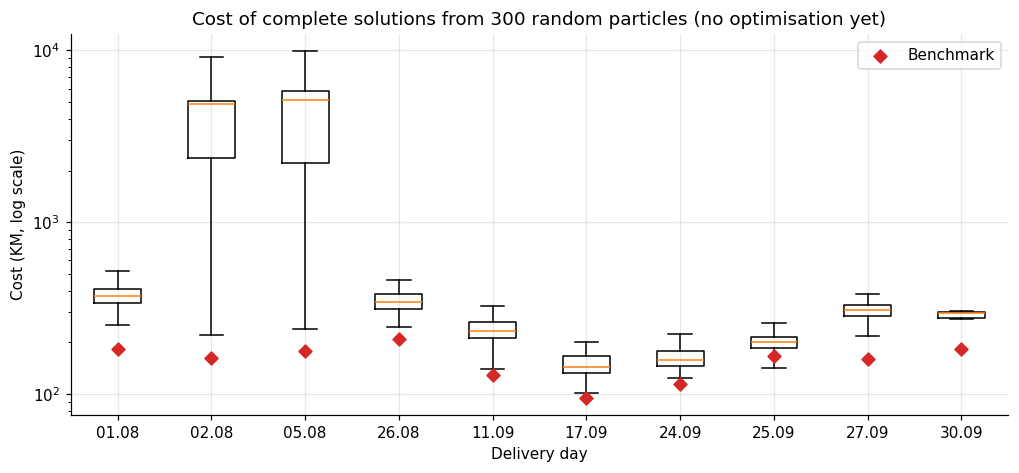

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot([r["costs"] for r in decoder_results], tick_labels=labels, showfliers=False)
ax.scatter(np.arange(1, len(ROUTE_IDS) + 1), decoder_check["benchmark"],
           marker="D", color="tab:red", zorder=3, label="Benchmark")
ax.set_yscale("log")
ax.set_xlabel("Delivery day")
ax.set_ylabel("Cost (KM, log scale)")
ax.set_title("Cost of complete solutions from 300 random particles (no optimisation yet)")
ax.legend()
save_figure(fig, "decoder_random_particles")
plt.show()

**Summary.** None of the 3,000 decoded solutions violates a hard constraint, and the decoder's cost
always equals the evaluator's cost. The particle has a large effect on the cost, so there is room
for PSO to optimise, and decoding is fast enough to give PSO a generous budget.

Two details stand out:

- On 02.08 and 05.08 many random particles cost thousands of KM. These are the particles that open
  vehicle `B02-A-000` (19.00 per km, see section 3) early. PSO has to learn to open it last or not at
  all, which the vehicle keys make possible.
- On 25.09 the best random particle is already cheaper than the benchmark. The benchmark is a strong
  reference but not an optimal solution.